from https://medium.com/data-science-collective/bayesian-linear-regression-from-scratch-in-python-a-comprehensive-guide-73a7e8fd7b4a

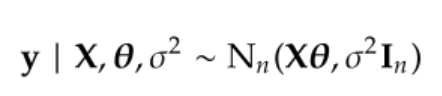

Good description of when to use Gibbs: 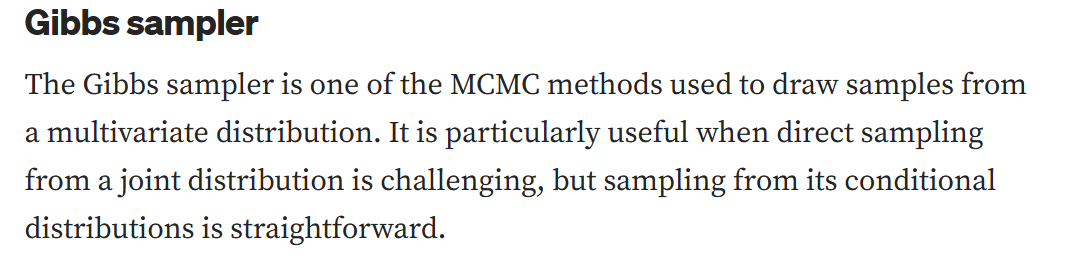

In [19]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
abalone = fetch_ucirepo(id=1) 
  
# data (as pandas dataframes) 
X = abalone.data.features 
y = abalone.data.targets 
  
# metadata 
print(abalone.metadata) 
  
# variable information 
print(abalone.variables) 

X.head()

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


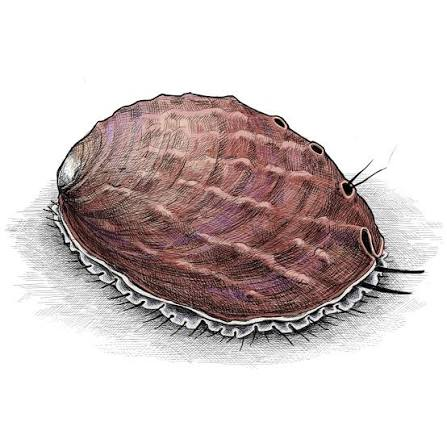

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Sex Distribution of Abalones')

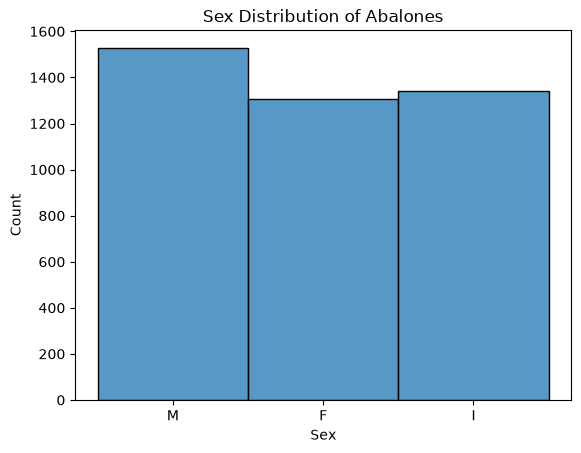

In [21]:
sns.histplot(data=X, x="Sex")
plt.title("Sex Distribution of Abalones")

In [22]:
import pandas as pd
abalone_sex = pd.get_dummies(X['Sex'])
abalone_sex = abalone_sex.drop(columns='I')
abalone_sex = abalone_sex.astype(int)
abalone_sex.columns = ['IsFemale', 'IsMale']
X = pd.concat([abalone_sex, X], axis=1)

In [25]:
X['Intercept'] = 1
X = X[["Intercept"] + [col for col in X.columns if col not in ['Intercept', 'Sex']]]
X.head()

,Intercept,IsFemale,IsMale,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight
0,1,0,1,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150
1,1,0,1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070
2,1,1,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210
3,1,0,1,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155
4,1,0,0,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055


In [51]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.linalg import inv
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf


class BayesianLinearRegression:

  def __init__(self, nIter=2**12, pBurn=None):
    self.nIter = nIter
    self.pBurn = pBurn if pBurn is not None else 0.5

  def fit(self, y, X, theta0=None, Sigma=None, alpha=None, beta=None):

    if isinstance(X, pd.DataFrame):
      self.colnames = list(X.columns)
      X = X.to_numpy()
    else:
      X = np.asarray(X)
      self.colnames = [f'x{k}' for k in range(X.shape[1])]

    if isinstance(y, (pd.Series, pd.DataFrame)):
      y = y.to_numpy().squeeze()
    else:
      y = np.asarray(y).squeeze()

    self.n, self.p = X.shape
    self.theta0 = theta0 if theta0 is not None else np.zeros(self.p)
    self.Sigma = Sigma if Sigma is not None else np.diag(np.ones(self.p))
    self.alpha = alpha if alpha is not None else 1
    self.beta = beta if beta is not None else 1
    theta = np.empty((self.nIter + 1, self.p))
    sigma2 = np.empty(self.nIter + 1)
    theta[0] = np.random.normal(size=self.p)
    sigma2[0] = np.random.exponential()

    for iIter in range(1, self.nIter + 1, 1):
      # update theta
      inv_Sigma = inv(self.Sigma)
      inv_comp1 = inv(np.matmul(X.T, X) / sigma2[iIter - 1] + inv_Sigma)
      comp2 = np.matmul(X.T, y) / sigma2[iIter - 1] + np.matmul(
          inv_Sigma, self.theta0
      )
      theta[iIter] = np.random.multivariate_normal(
          np.matmul(inv_comp1, comp2), inv_comp1
      )
      # update sigma2
      e = y - np.matmul(X, theta[iIter])
      alpha_n = self.alpha + self.n / 2
      beta_n = self.beta + np.matmul(e.T, e) / 2
      sigma2[iIter] = 1.0 / np.random.gamma(alpha_n, 1.0 / beta_n)

    self.thetaAll = pd.DataFrame(theta, columns=self.colnames)
    self.sigma2All = pd.DataFrame(sigma2, columns=['sigma2'])
    self.thetaBurn, self.theta = self._burn(self.thetaAll)
    self.sigma2Burn, self.sigma2 = self._burn(self.sigma2All)

  def _burn(self, theta):
    self.nBurn = int(self.nIter * self.pBurn)
    return theta.iloc[: self.nBurn, :], theta.iloc[self.nBurn :, :]

  def get_credible_interval(self):
    index_labels = ['2.5%', '50%', '97.5%']
    theta_ci = np.quantile(self.theta, [0.025, 0.5, 0.975], axis=0)
    sigma2_ci = np.quantile(self.sigma2, [0.025, 0.5, 0.975]).reshape((3, 1))
    self.theta_ci = pd.DataFrame(
        theta_ci, columns=self.colnames, index=index_labels
    )
    self.sigma2_ci = pd.DataFrame(
        sigma2_ci, columns=['sigma2'], index=index_labels
    )

  def plot_posterior(self, variables='all'):

    self.get_credible_interval()

    if variables == 'all':
      variables = self.colnames

    n_vars = len(variables) + 1
    n_fcols = int(np.ceil(np.sqrt(n_vars)))
    n_frows = int(np.ceil(n_vars / n_fcols))
    fig, axs = plt.subplots(
        n_frows, n_fcols, figsize=(4 * n_fcols, 4 * n_frows), squeeze=False
    )
    axs_flat = axs.ravel()

    self.sigma2.plot(
        kind='kde', ax=axs_flat[0], label=r'$f(\sigma^2\mid\mathrm{y},\mathrm{X})$'
    )
    axs_flat[0].axvline(
        self.sigma2_ci.loc['50%', 'sigma2'],
        color='red',
        linestyle='dashed',
        linewidth=2,
        label=r'$\widehat{\sigma}^2$',
    )
    axs_flat[0].set_title(r'$\sigma^2$')
    axs_flat[0].legend(loc='upper right')

    for idx, col in enumerate(variables, start=1):
      self.theta[col].plot(
          kind='kde', ax=axs_flat[idx], label=r'$f(\theta\mid\mathrm{y},\mathrm{X})$'
      )
      axs_flat[idx].axvline(
          self.theta_ci.loc['50%', col],
          color='red',
          linestyle='dashed',
          linewidth=2,
          label=r'$\widehat{\theta}$',
      )
      axs_flat[idx].set_title(col)
      axs_flat[idx].legend(loc='upper right')

  def trace_plot(self, first_n=200):

    fig, axs = plt.subplots(1, 2, squeeze=False, figsize=(5 * 2, 3))

    # First n=200 samples
    thetaFirst200 = self.thetaBurn.iloc[0:first_n, :]
    sigma2First200 = self.sigma2Burn.iloc[0:first_n, :]
    axs[0, 0].plot(
        sigma2First200.index,
        sigma2First200['sigma2'],
        label=r'$\sigma^2$',
        linestyle='-',
    )
    for col in thetaFirst200.columns:
      axs[0, 0].plot(
          thetaFirst200.index, thetaFirst200[col], label=col, linestyle='-'
      )
    axs[0, 0].set_xlabel('Index')
    axs[0, 0].set_ylabel('Value')
    axs[0, 0].set_title('Trace plot of ' + r'$\theta_{1:%s}$' % first_n)
    axs[0, 0].grid(True)

    # Latter part of the Markov-chain
    axs[0, 1].plot(
        self.sigma2.index,
        self.sigma2['sigma2'],
        label=r'$\sigma^2$',
        linestyle='-',
    )
    for col in self.theta.columns:
      axs[0, 1].plot(
          self.theta.index, self.theta[col], label=col, linestyle='-'
      )
    axs[0, 1].set_xlabel('Index')
    axs[0, 1].set_ylabel('Value')
    axs[0, 1].set_title(
        'Trace plot of $\\theta_{{{}:{}}}$'.format(
            self.theta.index[0], self.theta.index[-1]
        )
    )
    axs[0, 1].legend(bbox_to_anchor=(1, 0.5), loc='center left')
    axs[0, 1].grid(True)

  def acf_plot(self):

    n_vars = self.p + 1
    n_fcols = int(np.ceil(np.sqrt(n_vars)))
    n_frows = int(np.ceil(n_vars / n_fcols))
    fig, axs = plt.subplots(
        n_frows, n_fcols, figsize=(4 * n_fcols, 4 * n_frows), squeeze=False
    )
    axs_flat = axs.ravel()

    plot_acf(self.sigma2All['sigma2'], lags=20, ax=axs_flat[0])
    axs_flat[0].set_title(r'$\sigma^2$')
    axs_flat[0].set_ylim([-0.1, 1.1])

    for idx, col in enumerate(self.thetaAll.columns, start=1):
      plot_acf(self.thetaAll[col], lags=20, ax=axs_flat[idx])
      axs_flat[idx].set_title(col)
      axs_flat[idx].set_ylim([-0.1, 1.1])

In [52]:
Y = y['Rings']

In [53]:
nIter = 2**14
pBurn = 0.5
model = BayesianLinearRegression(nIter, pBurn)
model.fit(Y, X)

In [55]:
model.get_credible_interval()
print(model.theta_ci)

       Intercept  IsFemale    IsMale    Length  Diameter    Height  \
2.5%    3.293616  0.792766  0.797188  2.227889  3.301274  2.830432   
50%     3.730589  0.998813  0.985588  3.644234  4.923719  4.468095   
97.5%   4.177813  1.201954  1.167866  5.037579  6.515141  6.141692   

       Whole_weight  Shucked_weight  Viscera_weight  Shell_weight  
2.5%       3.909251      -14.341813       -4.659772      8.671040  
50%        4.703351      -13.214330       -3.090364     10.023955  
97.5%      5.546433      -12.121392       -1.587575     11.384935  


In [56]:
print(model.sigma2_ci)

         sigma2
2.5%   4.784490
50%    4.999302
97.5%  5.225567


In [64]:
import statsmodels.api as sm
ols = sm.OLS(Y,X).fit()
print(ols.params)

Intercept          3.069765
IsFemale           0.824876
IsMale             0.882592
Length            -0.458335
Diameter          11.075103
Height            10.761537
Whole_weight       8.975445
Shucked_weight   -19.786867
Viscera_weight   -10.581827
Shell_weight       8.741806
dtype: float64


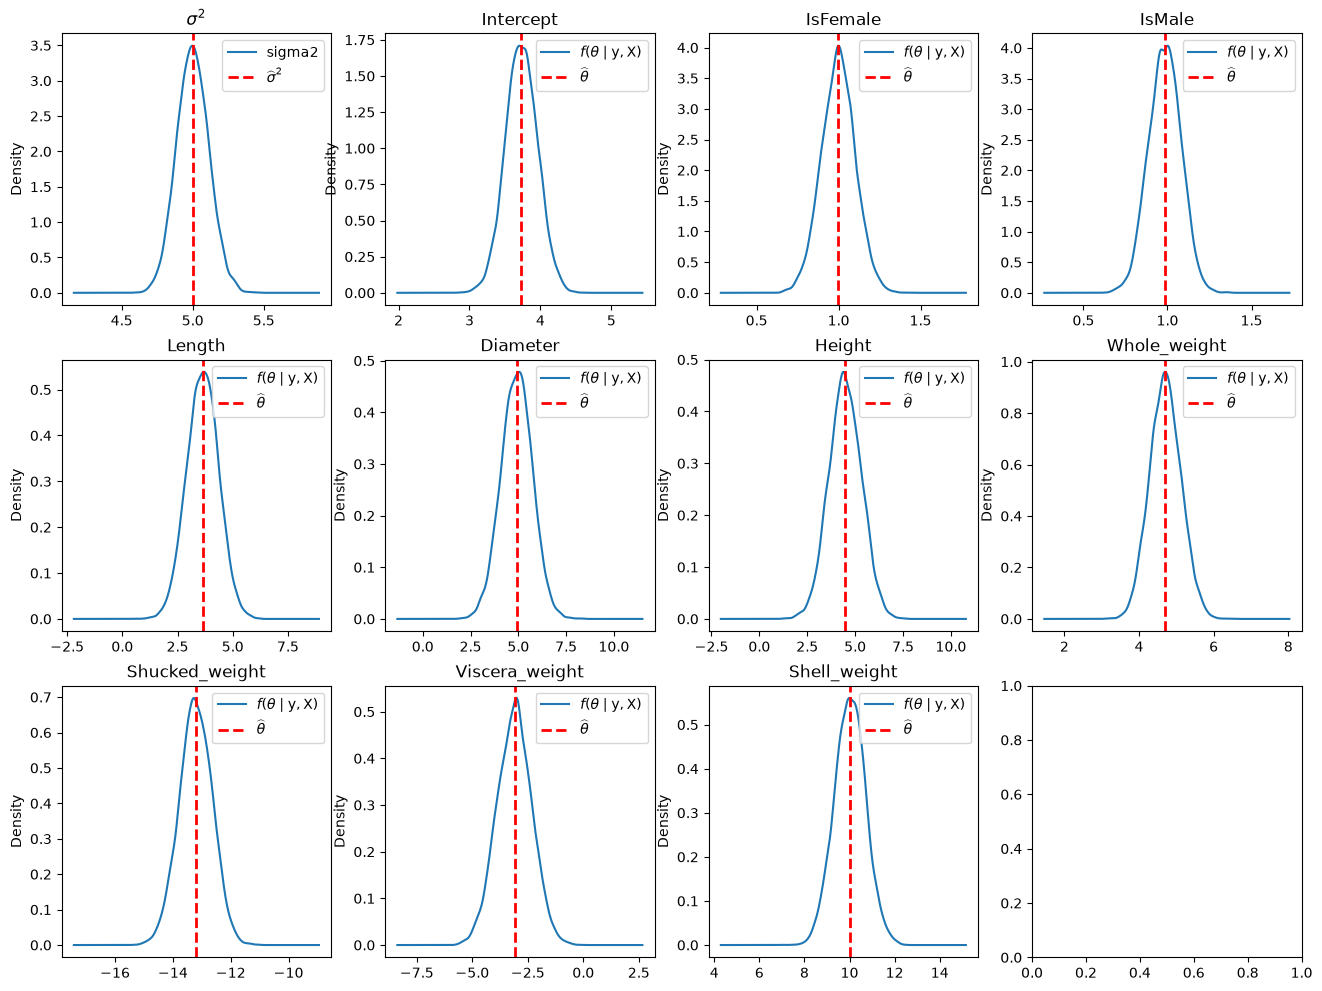

In [65]:
model.plot_posterior()

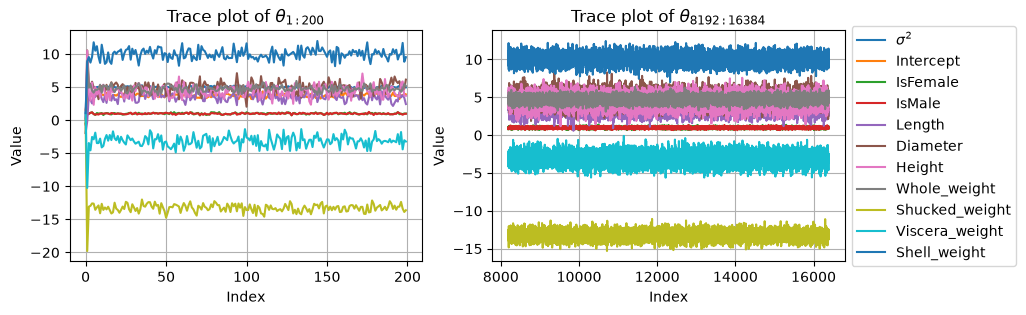

In [67]:
model.trace_plot()

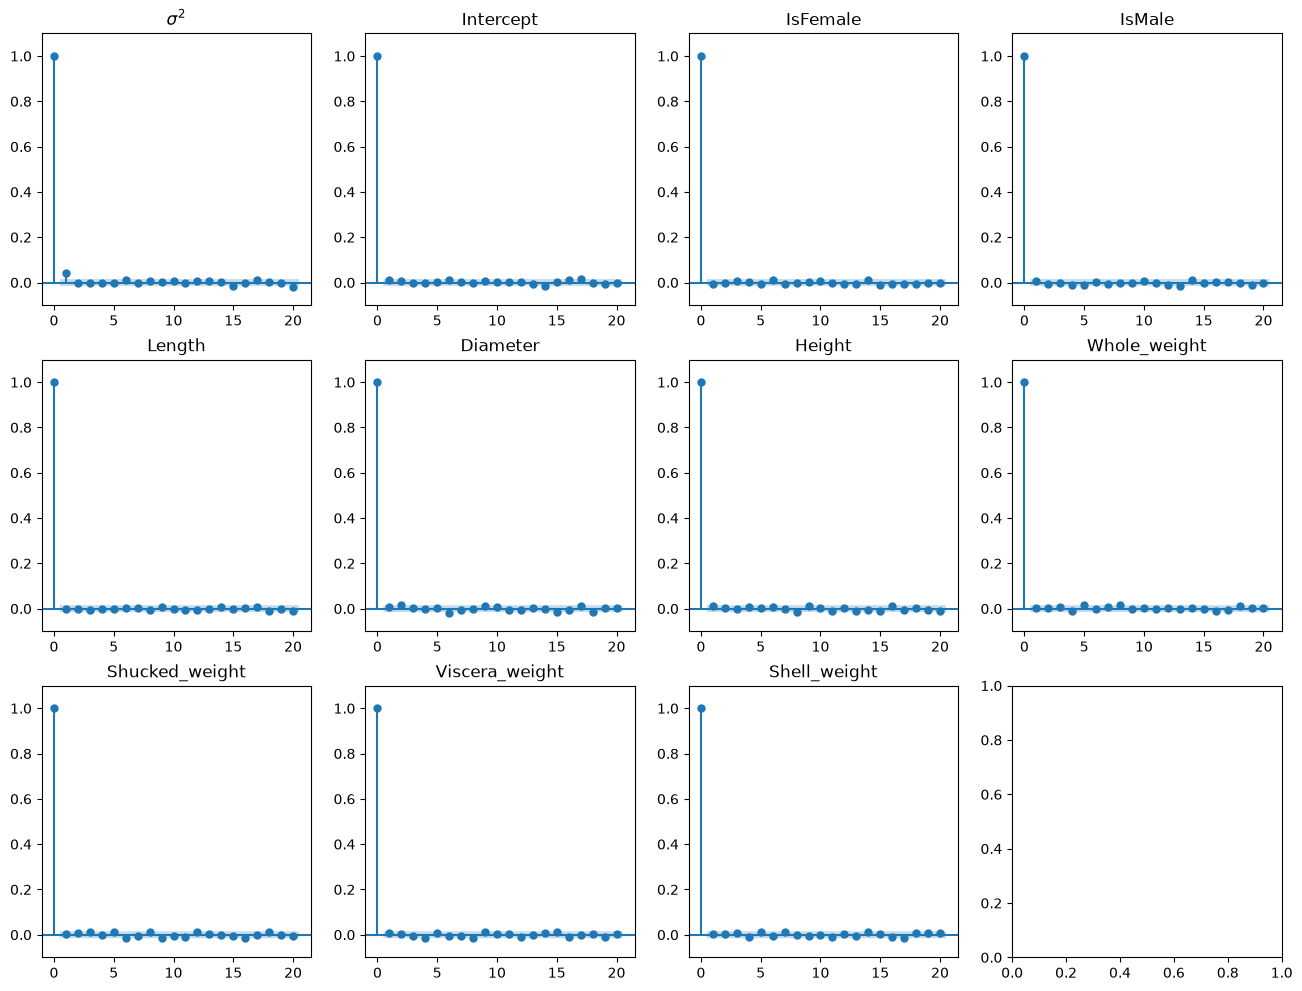

In [68]:
model.acf_plot()